In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Load Data
df = pd.read_csv('https://github.com/YBIFoundation/ProjectDataSet/raw/main/Marketing%20Data%20Analysis.csv')
print("Data loaded successfully!")
print("Shape:", df.shape)
df.head()

Data loaded successfully!
Shape: (1000, 11)


,Unnamed: 0,Date,Channel,Region,Ad_Spend,Impressions,Clicks,Conversions,Revenue,CTR,Conversion_Rate
0,0,2025-01-01,Facebook,East,35072,324422,12194,1177,487278,4,10
1,1,2025-01-01,YouTube,North,15612,434523,5654,2927,2517220,1,52
2,2,2025-01-01,Instagram,East,5582,65898,9991,761,318859,15,8
3,3,2025-01-02,YouTube,East,21320,105984,7077,2505,2367225,7,35
4,4,2025-01-04,YouTube,South,10838,298801,16150,2179,1717052,5,13


In [3]:
# Step 3: Data Understanding
print("=== Dataset Info ===")
print(df.shape)

print("\n=== Column Names ===")
print(df.columns.tolist())

print("\n=== Data Types ===")
print(df.dtypes)

print("\n=== Missing Values ===")
print(df.isnull().sum())

print("\n=== Basic Statistics ===")
df.describe()

=== Dataset Info ===
(1000, 11)

=== Column Names ===
['Unnamed: 0', 'Date', 'Channel', 'Region', 'Ad_Spend', 'Impressions', 'Clicks', 'Conversions', 'Revenue', 'CTR', 'Conversion_Rate']

=== Data Types ===
Unnamed: 0          int64
Date               object
Channel            object
Region             object
Ad_Spend            int64
Impressions         int64
Clicks              int64
Conversions         int64
Revenue             int64
CTR                 int64
Conversion_Rate     int64
dtype: object

=== Missing Values ===
Unnamed: 0         0
Date               0
Channel            0
Region             0
Ad_Spend           0
Impressions        0
Clicks             0
Conversions        0
Revenue            0
CTR                0
Conversion_Rate    0
dtype: int64

=== Basic Statistics ===


,Unnamed: 0,Ad_Spend,Impressions,Clicks,Conversions,Revenue,CTR,Conversion_Rate
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1.000000e+03,1000.000000,1000.000000
mean,499.500000,27373.362000,263305.952000,10205.10800,1520.087000,9.165629e+05,7.749000,28.621000
std,288.819436,12908.653881,139791.528738,5741.32884,862.106435,6.606403e+05,13.752714,43.401671
min,0.000000,5102.000000,10748.000000,533.00000,54.000000,1.956000e+04,0.000000,0.000000
25%,249.750000,16286.000000,147697.000000,5090.25000,791.750000,3.845415e+05,2.000000,7.750000
50%,499.500000,27914.500000,266647.000000,10208.50000,1475.000000,7.477765e+05,4.000000,15.000000
75%,749.250000,38630.000000,382078.250000,15254.75000,2262.000000,1.301754e+06,7.000000,29.000000
max,999.000000,49930.000000,499747.000000,19982.00000,2998.000000,2.810090e+06,151.000000,464.000000


In [4]:
# Step 4: Data Preprocessing
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month_name()
df['Month_Num'] = df['Date'].dt.month
df['ROAS'] = df['Revenue'] / df['Ad_Spend']

print("=== New Columns Added ===")
print(df.columns.tolist())

print("\n=== Sample Data ===")
df.head()

=== New Columns Added ===
['Unnamed: 0', 'Date', 'Channel', 'Region', 'Ad_Spend', 'Impressions', 'Clicks', 'Conversions', 'Revenue', 'CTR', 'Conversion_Rate', 'Month', 'Month_Num', 'ROAS']

=== Sample Data ===


,Unnamed: 0,Date,Channel,Region,Ad_Spend,Impressions,Clicks,Conversions,Revenue,CTR,Conversion_Rate,Month,Month_Num,ROAS
0,0,2025-01-01,Facebook,East,35072,324422,12194,1177,487278,4,10,January,1,13.893647
1,1,2025-01-01,YouTube,North,15612,434523,5654,2927,2517220,1,52,January,1,161.236229
2,2,2025-01-01,Instagram,East,5582,65898,9991,761,318859,15,8,January,1,57.122716
3,3,2025-01-02,YouTube,East,21320,105984,7077,2505,2367225,7,35,January,1,111.033068
4,4,2025-01-04,YouTube,South,10838,298801,16150,2179,1717052,5,13,January,1,158.428861


In [5]:
# Step 5: Channel wise Analysis
channel_df = df.groupby('Channel')[['Revenue','Ad_Spend','Conversions','Clicks']].sum()
channel_df['ROAS'] = channel_df['Revenue'] / channel_df['Ad_Spend']
channel_df = channel_df.sort_values('Revenue', ascending=False)

print("=== Channel Performance ===")
print(channel_df)

=== Channel Performance ===
              Revenue  Ad_Spend  Conversions   Clicks       ROAS
Channel                                                         
Email       203807018   5751108       327658  2052734  35.437870
Google Ads  188713791   5015347       308477  1990854  37.627265
Facebook    187586332   5559037       307294  2136462  33.744393
YouTube     173481734   5526441       290900  2019327  31.391222
Instagram   162974026   5521429       285758  2005731  29.516639


In [6]:
# Step 6: Region wise Analysis
region_df = df.groupby('Region')[['Revenue','Ad_Spend','Conversions']].sum()
region_df['ROAS'] = region_df['Revenue'] / region_df['Ad_Spend']
region_df = region_df.sort_values('Revenue', ascending=False)

print("=== Region Performance ===")
print(region_df)

=== Region Performance ===
          Revenue  Ad_Spend  Conversions       ROAS
Region                                             
East    263871263   7669327       423942  34.406052
West    221914505   6540265       386364  33.930507
South   217101083   6538146       366848  33.205297
North   213676050   6625624       342933  32.249951


In [7]:
# Step 7: Monthly Trend Analysis
monthly_df = df.groupby('Month_Num')[['Revenue','Conversions','Ad_Spend']].sum().reset_index()
monthly_df = monthly_df.sort_values('Month_Num')
monthly_df['Month'] = pd.to_datetime(monthly_df['Month_Num'], format='%m').dt.strftime('%b')

print("=== Monthly Performance ===")
print(monthly_df[['Month','Revenue','Conversions','Ad_Spend']])

=== Monthly Performance ===
   Month   Revenue  Conversions  Ad_Spend
0    Jan  74323582       121509   2154817
1    Feb  71637926       123460   2176560
2    Mar  70932146       127037   2446349
3    Apr  83431965       126557   2525415
4    May  74129683       125330   2282405
5    Jun  81856314       141115   2356237
6    Jul  88303685       142137   2729558
7    Aug  84900506       139391   2473328
8    Sep  73104838       115175   2106982
9    Oct  81483710       132860   2185846
10   Nov  67038012       114666   1880062
11   Dec  65420534       110850   2055803


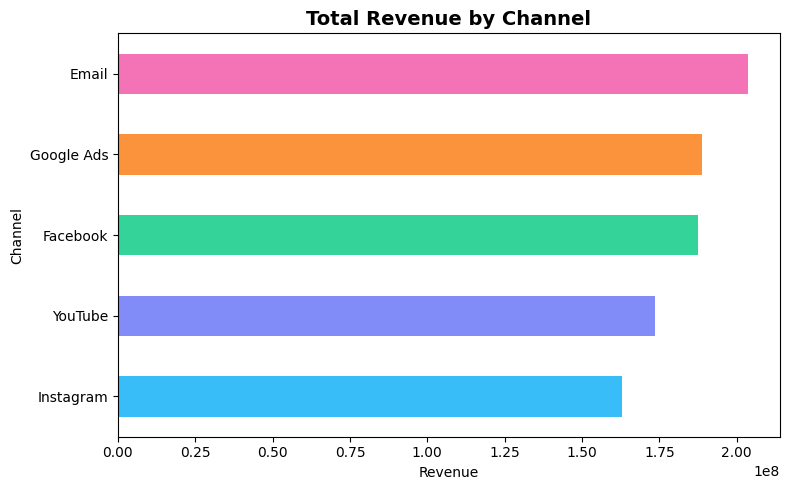

In [8]:
# Step 8: Chart 1 - Revenue by Channel
plt.figure(figsize=(8,5))
channel_df['Revenue'].sort_values().plot(kind='barh', color=['#38bdf8','#818cf8','#34d399','#fb923c','#f472b6'])
plt.title('Total Revenue by Channel', fontsize=14, fontweight='bold')
plt.xlabel('Revenue')
plt.ylabel('Channel')
plt.tight_layout()
plt.show()

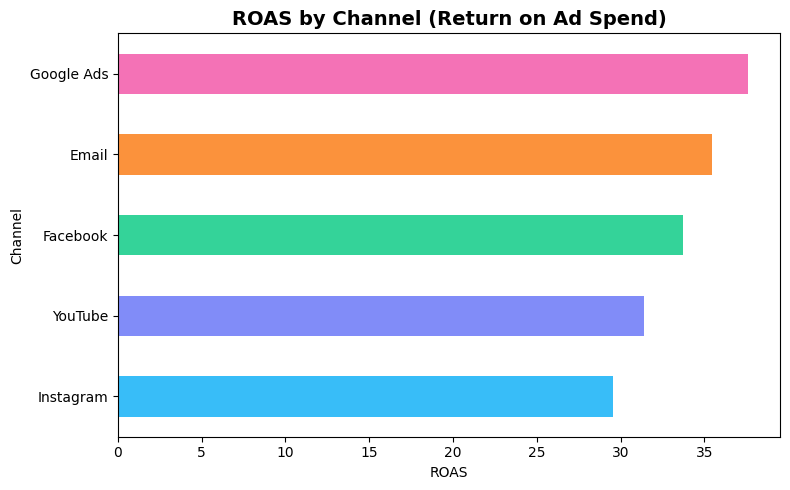

In [10]:
# Step 8: Chart 2 - ROAS by Channel
plt.figure(figsize=(8,5))
channel_df['ROAS'].sort_values().plot(kind='barh', color=['#38bdf8','#818cf8','#34d399','#fb923c','#f472b6'])
plt.title('ROAS by Channel (Return on Ad Spend)', fontsize=14, fontweight='bold')
plt.xlabel('ROAS')
plt.ylabel('Channel')
plt.tight_layout()
plt.show()

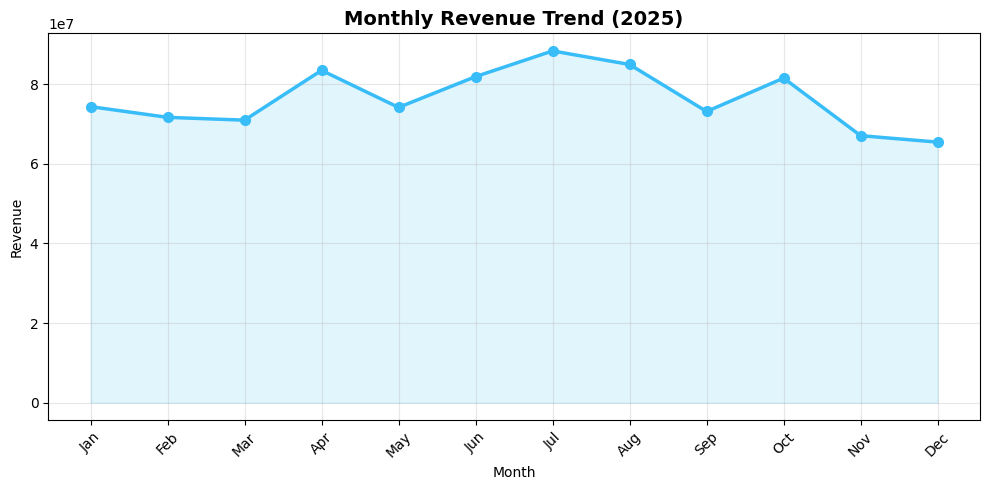

In [11]:
# Step 8: Chart 3 - Monthly Revenue Trend
plt.figure(figsize=(10,5))
plt.plot(monthly_df['Month'], monthly_df['Revenue'],
         color='#38bdf8', linewidth=2.5, marker='o', markersize=7)
plt.fill_between(range(len(monthly_df)), monthly_df['Revenue'],
                 alpha=0.15, color='#38bdf8')
plt.xticks(range(len(monthly_df)), monthly_df['Month'], rotation=45)
plt.title('Monthly Revenue Trend (2025)', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

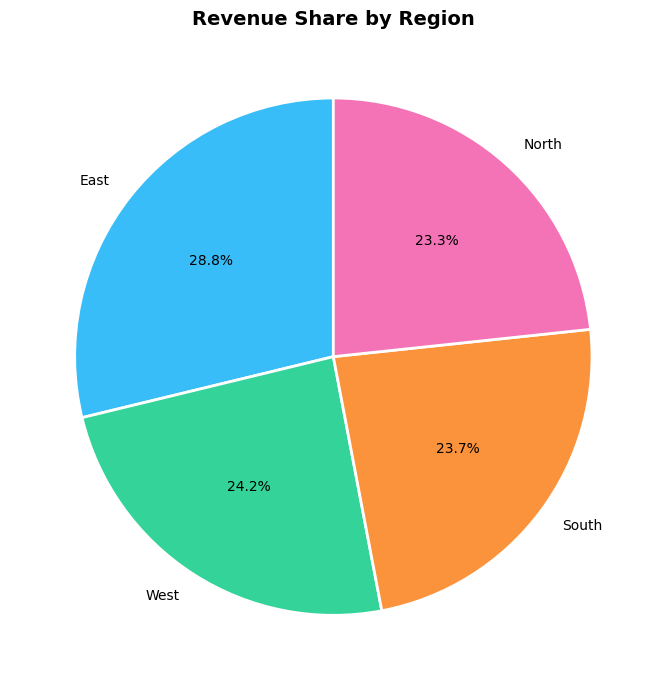

In [12]:
# Step 8: Chart 4 - Revenue by Region
plt.figure(figsize=(7,7))
region_df['Revenue'].plot(kind='pie',
                          autopct='%1.1f%%',
                          colors=['#38bdf8','#34d399','#fb923c','#f472b6'],
                          startangle=90,
                          wedgeprops=dict(edgecolor='white', linewidth=2))
plt.title('Revenue Share by Region', fontsize=14, fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.show()

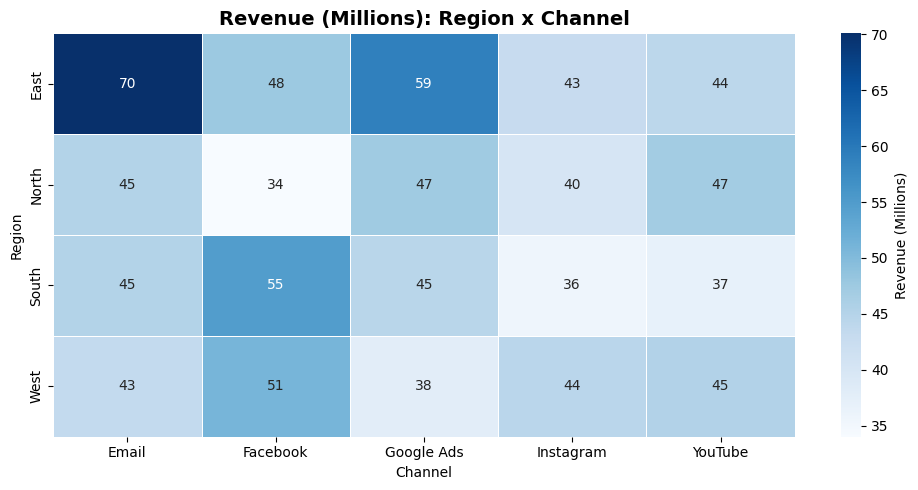

In [13]:
# Step 8: Chart 5 - Region x Channel Heatmap
plt.figure(figsize=(10,5))
pivot = df.groupby(['Region','Channel'])['Revenue'].sum().unstack()/1e6
sns.heatmap(pivot,
            annot=True,
            fmt='.0f',
            cmap='Blues',
            linewidths=0.5,
            linecolor='white',
            cbar_kws={'label':'Revenue (Millions)'})
plt.title('Revenue (Millions): Region x Channel', fontsize=14, fontweight='bold')
plt.xlabel('Channel')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

In [14]:
# Step 9: Key Insights & Conclusion
print("=" * 50)
print("       SHOPEASE MARKETING ANALYSIS REPORT")
print("=" * 50)

print("\n📊 DATASET OVERVIEW")
print(f"Total Records: {len(df)}")
print(f"Time Period: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Total Channels: {df['Channel'].nunique()}")
print(f"Total Regions: {df['Region'].nunique()}")

print("\n💰 REVENUE INSIGHTS")
print(f"Total Revenue: ₹{df['Revenue'].sum()/1e6:.1f} Million")
print(f"Total Ad Spend: ₹{df['Ad_Spend'].sum()/1e6:.1f} Million")
print(f"Overall ROAS: {df['Revenue'].sum()/df['Ad_Spend'].sum():.1f}x")

print("\n🏆 BEST PERFORMING CHANNEL")
best_ch = channel_df['Revenue'].idxmax()
print(f"Highest Revenue: {best_ch} — ₹{channel_df['Revenue'].max()/1e6:.1f}M")
best_roas = channel_df['ROAS'].idxmax()
print(f"Highest ROAS: {best_roas} — {channel_df['ROAS'].max():.1f}x")

print("\n🌍 BEST PERFORMING REGION")
best_reg = region_df['Revenue'].idxmax()
print(f"Highest Revenue: {best_reg} — ₹{region_df['Revenue'].max()/1e6:.1f}M")

print("\n📈 MONTHLY TREND")
best_month = monthly_df.loc[monthly_df['Revenue'].idxmax(), 'Month']
worst_month = monthly_df.loc[monthly_df['Revenue'].idxmin(), 'Month']
print(f"Best Month: {best_month}")
print(f"Worst Month: {worst_month}")

print("\n✅ RECOMMENDATIONS")
print(f"1. Invest more in {best_roas} — highest ROAS")
print(f"2. Focus campaigns on {best_reg} region")
print(f"3. Increase budget in {best_month} month")
print(f"4. Review strategy for low performing channels")
print("\n" + "=" * 50)
print("Analysis Complete!")
print("=" * 50)

       SHOPEASE MARKETING ANALYSIS REPORT

📊 DATASET OVERVIEW
Total Records: 1000
Time Period: 2025-01-01 to 2025-12-31
Total Channels: 5
Total Regions: 4

💰 REVENUE INSIGHTS
Total Revenue: ₹916.6 Million
Total Ad Spend: ₹27.4 Million
Overall ROAS: 33.5x

🏆 BEST PERFORMING CHANNEL
Highest Revenue: Email — ₹203.8M
Highest ROAS: Google Ads — 37.6x

🌍 BEST PERFORMING REGION
Highest Revenue: East — ₹263.9M

📈 MONTHLY TREND
Best Month: Jul
Worst Month: Dec

✅ RECOMMENDATIONS
1. Invest more in Google Ads — highest ROAS
2. Focus campaigns on East region
3. Increase budget in Jul month
4. Review strategy for low performing channels

Analysis Complete!
